In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

import pickle

In [2]:
books = pd.read_csv(
    "Books.csv",
    low_memory=False
)

users = pd.read_csv(
    "Users.csv",
    low_memory=False
)

ratings = pd.read_csv(
    "Ratings.csv",
    low_memory=False
)

print("Datasets loaded successfully")

Datasets loaded successfully


In [3]:
print("Books Shape   :", books.shape)
print("Users Shape   :", users.shape)
print("Ratings Shape :", ratings.shape)

Books Shape   : (271360, 8)
Users Shape   : (278858, 3)
Ratings Shape : (1149780, 3)


In [4]:
print("BOOKS")
display(books.head())

print("\nUSERS")
display(users.head())

print("\nRATINGS")
display(ratings.head())

BOOKS


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...



USERS


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN



RATINGS


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [5]:
print("BOOKS INFORMATION")
books.info()

print("\nUSERS INFORMATION")
users.info()

print("\nRATINGS INFORMATION")
ratings.info()

BOOKS INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 271360 entries, 0 to 271359
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   ISBN                 271360 non-null  str  
 1   Book-Title           271360 non-null  str  
 2   Book-Author          271358 non-null  str  
 3   Year-Of-Publication  271360 non-null  str  
 4   Publisher            271358 non-null  str  
 5   Image-URL-S          271360 non-null  str  
 6   Image-URL-M          271360 non-null  str  
 7   Image-URL-L          271357 non-null  str  
dtypes: str(8)
memory usage: 84.4 MB

USERS INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 278858 entries, 0 to 278857
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   User-ID   278858 non-null  int64  
 1   Location  278858 non-null  str    
 2   Age       168096 non-null  float64
dtypes: float64(1), int64(1), str(1)
m

In [6]:
print("Books Missing Values")
display(books.isnull().sum())

print("\nUsers Missing Values")
display(users.isnull().sum())

print("\nRatings Missing Values")
display(ratings.isnull().sum())

Books Missing Values


ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64


Users Missing Values


User-ID          0
Location         0
Age         110762
dtype: int64


Ratings Missing Values


User-ID        0
ISBN           0
Book-Rating    0
dtype: int64

In [7]:
print(
    "Books Duplicates:",
    books.duplicated().sum()
)

print(
    "Users Duplicates:",
    users.duplicated().sum()
)

print(
    "Ratings Duplicates:",
    ratings.duplicated().sum()
)

Books Duplicates: 0
Users Duplicates: 0
Ratings Duplicates: 0


In [8]:
books.drop_duplicates(
    inplace=True
)

users.drop_duplicates(
    inplace=True
)

ratings.drop_duplicates(
    inplace=True
)

print("Duplicates removed")

Duplicates removed


In [9]:
users["Age"] = pd.to_numeric(
    users["Age"],
    errors="coerce"
)

# Invalid ages
users.loc[
    (users["Age"] < 5) |
    (users["Age"] > 100),
    "Age"
] = np.nan

# Fill missing ages
median_age = users["Age"].median()

users["Age"] = users["Age"].fillna(
    median_age
)

print("Median Age:", median_age)

display(
    users["Age"].describe()
)

Median Age: 32.0


count    278858.000000
mean         33.643385
std          10.630979
min           5.000000
25%          29.000000
50%          32.000000
75%          35.000000
max         100.000000
Name: Age, dtype: float64

In [11]:
users["Age-Group"] = pd.cut(
    users["Age"],
    bins=[
        9,
        18,
        25,
        35,
        50,
        65,
        100
    ],
    labels=[
        "10-18",
        "19-25",
        "26-35",
        "36-50",
        "51-65",
        "66-100"
    ]
)

users.head()

,User-ID,Location,Age,Age-Group
0,1,"nyc, new york, usa",32.0,26-35
1,2,"stockton, california, usa",18.0,10-18
2,3,"moscow, yukon territory, russia",32.0,26-35
3,4,"porto, v.n.gaia, portugal",17.0,10-18
4,5,"farnborough, hants, united kingdom",32.0,26-35


In [12]:
users["Country"] = (
    users["Location"]
    .astype(str)
    .str.split(",")
    .str[-1]
    .str.strip()
)

users[
    [
        "Location",
        "Country"
    ]
].head()

,Location,Country
0,"nyc, new york, usa",usa
1,"stockton, california, usa",usa
2,"moscow, yukon territory, russia",russia
3,"porto, v.n.gaia, portugal",portugal
4,"farnborough, hants, united kingdom",united kingdom


In [15]:
books["Book-Author"] = (
    books["Book-Author"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

books["Publisher"] = (
    books["Publisher"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

books["Book-Title"] = (
    books["Book-Title"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

books["ISBN"] = (
    books["ISBN"]
    .astype(str)
    .str.strip()
    .str.upper()
)

In [16]:
books[
    "Year-Of-Publication"
] = pd.to_numeric(
    books[
        "Year-Of-Publication"
    ],
    errors="coerce"
)

books.loc[
    (
        books[
            "Year-Of-Publication"
        ] < 1800
    )
    |
    (
        books[
            "Year-Of-Publication"
        ] > 2026
    ),
    "Year-Of-Publication"
] = np.nan

median_year = (
    books[
        "Year-Of-Publication"
    ].median()
)

books[
    "Year-Of-Publication"
] = (
    books[
        "Year-Of-Publication"
    ]
    .fillna(median_year)
)

books[
    "Publication-Decade"
] = (
    books[
        "Year-Of-Publication"
    ] // 10
) * 10

In [17]:
ratings["ISBN"] = (
    ratings["ISBN"]
    .astype(str)
    .str.strip()
    .str.upper()
)

ratings["User-ID"] = pd.to_numeric(
    ratings["User-ID"],
    errors="coerce"
)

ratings["Book-Rating"] = pd.to_numeric(
    ratings["Book-Rating"],
    errors="coerce"
)

ratings.dropna(
    subset=[
        "User-ID",
        "ISBN",
        "Book-Rating"
    ],
    inplace=True
)

ratings["User-ID"] = (
    ratings["User-ID"]
    .astype(int)
)

In [18]:
books_ratings = ratings.merge(
    books,
    on="ISBN",
    how="inner"
)

final_df = books_ratings.merge(
    users,
    on="User-ID",
    how="inner"
)

print(
    "Final Dataset Shape:",
    final_df.shape
)

display(
    final_df.head()
)

Final Dataset Shape: (1044974, 15)


,User-ID,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,Publication-Decade,Location,Age,Age-Group,Country
0,276725,034545104X,0,Flesh Tones: A Novel,M. J. Rose,2002.0,Ballantine Books,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...,2000.0,"tyler, texas, usa",32.0,26-35,usa
1,276726,0155061224,5,Rites of Passage,Judith Rae,2001.0,Heinle,http://images.amazon.com/images/P/0155061224.0...,http://images.amazon.com/images/P/0155061224.0...,http://images.amazon.com/images/P/0155061224.0...,2000.0,"seattle, washington, usa",32.0,26-35,usa
2,276727,0446520802,0,The Notebook,Nicholas Sparks,1996.0,Warner Books,http://images.amazon.com/images/P/0446520802.0...,http://images.amazon.com/images/P/0446520802.0...,http://images.amazon.com/images/P/0446520802.0...,1990.0,"h, new south wales, australia",16.0,10-18,australia
3,276729,052165615X,3,Help!: Level 1,Philip Prowse,1999.0,Cambridge University Press,http://images.amazon.com/images/P/052165615X.0...,http://images.amazon.com/images/P/052165615X.0...,http://images.amazon.com/images/P/052165615X.0...,1990.0,"rijeka, n/a, croatia",16.0,10-18,croatia
4,276729,0521795028,6,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001.0,Cambridge University Press,http://images.amazon.com/images/P/0521795028.0...,http://images.amazon.com/images/P/0521795028.0...,http://images.amazon.com/images/P/0521795028.0...,2000.0,"rijeka, n/a, croatia",16.0,10-18,croatia


In [19]:
ml_df = final_df.drop(
    columns=[
        "Image-URL-S",
        "Image-URL-M",
        "Image-URL-L"
    ],
    errors="ignore"
).copy()

print(
    ml_df.shape
)

display(
    ml_df.head()
)

(1044974, 12)


,User-ID,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,Publication-Decade,Location,Age,Age-Group,Country
0,276725,034545104X,0,Flesh Tones: A Novel,M. J. Rose,2002.0,Ballantine Books,2000.0,"tyler, texas, usa",32.0,26-35,usa
1,276726,0155061224,5,Rites of Passage,Judith Rae,2001.0,Heinle,2000.0,"seattle, washington, usa",32.0,26-35,usa
2,276727,0446520802,0,The Notebook,Nicholas Sparks,1996.0,Warner Books,1990.0,"h, new south wales, australia",16.0,10-18,australia
3,276729,052165615X,3,Help!: Level 1,Philip Prowse,1999.0,Cambridge University Press,1990.0,"rijeka, n/a, croatia",16.0,10-18,croatia
4,276729,0521795028,6,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001.0,Cambridge University Press,2000.0,"rijeka, n/a, croatia",16.0,10-18,croatia


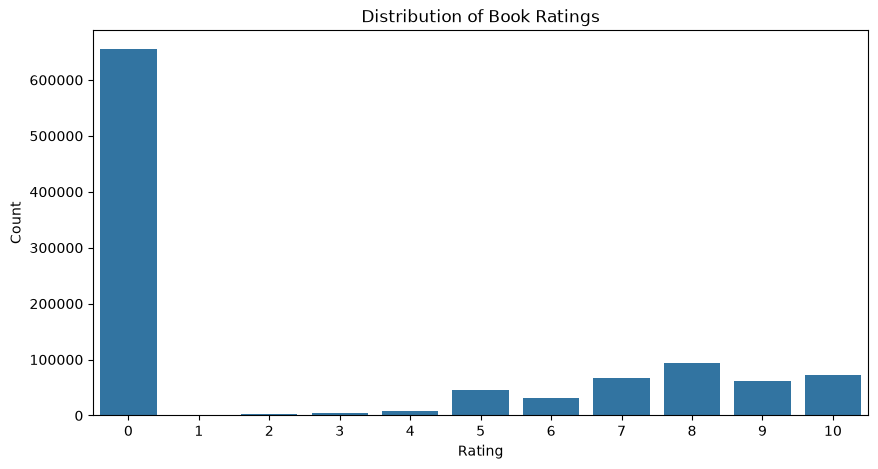

In [20]:
plt.figure(
    figsize=(10, 5)
)

sns.countplot(
    data=ml_df,
    x="Book-Rating"
)

plt.title(
    "Distribution of Book Ratings"
)

plt.xlabel("Rating")
plt.ylabel("Count")

plt.show()

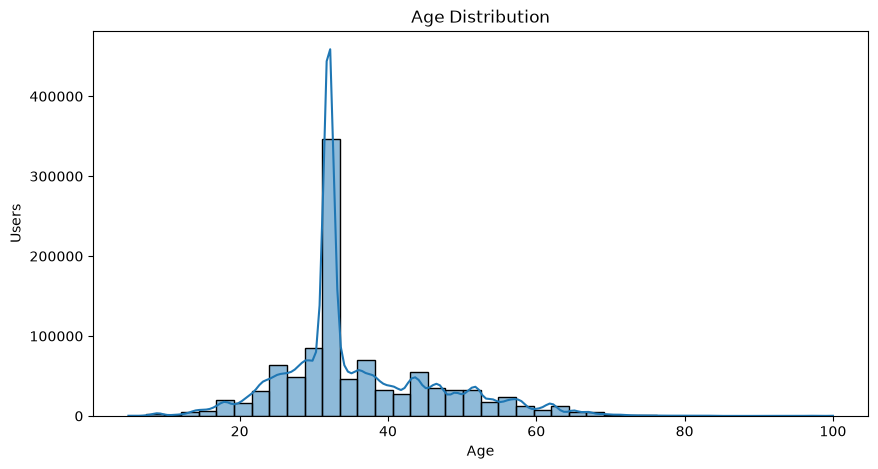

In [21]:
plt.figure(
    figsize=(10, 5)
)

sns.histplot(
    data=ml_df,
    x="Age",
    bins=40,
    kde=True
)

plt.title(
    "Age Distribution"
)

plt.xlabel("Age")
plt.ylabel("Users")

plt.show()

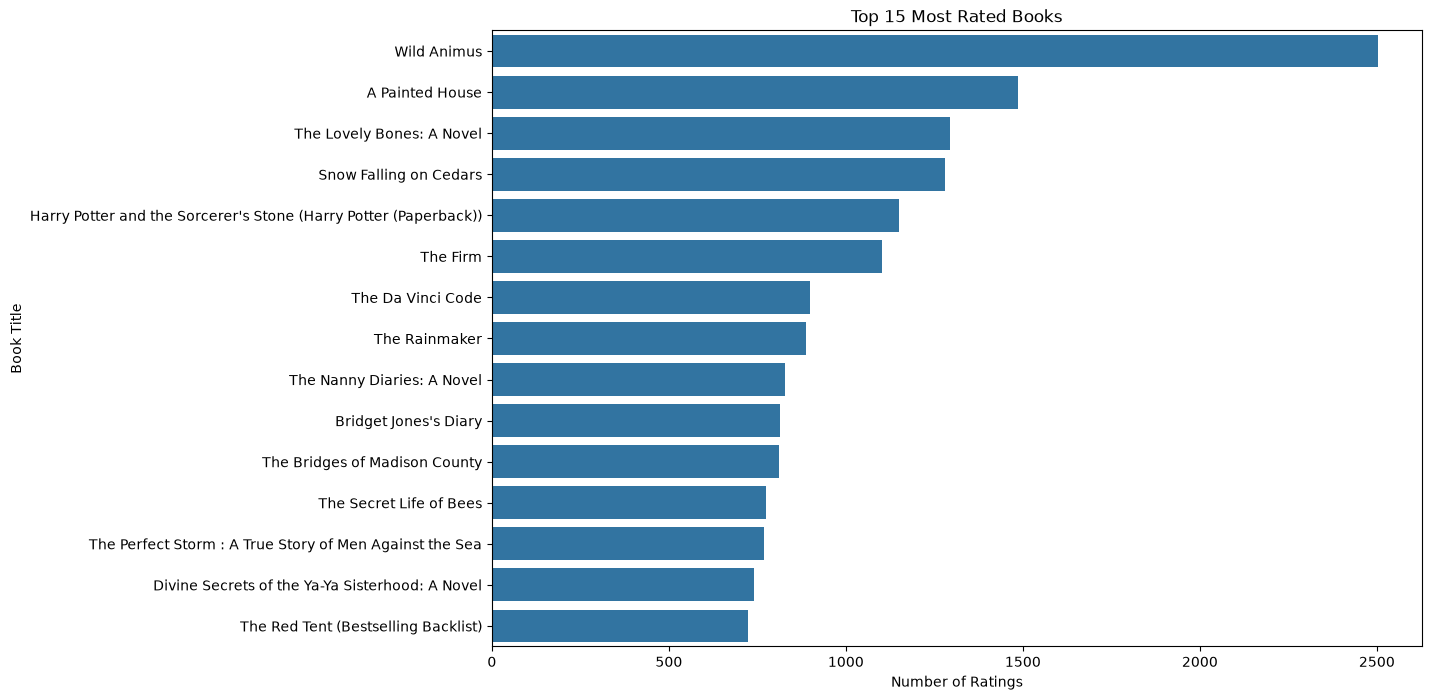

In [22]:
top_books = (
    ml_df
    .groupby("Book-Title")
    .size()
    .sort_values(
        ascending=False
    )
    .head(15)
)

plt.figure(
    figsize=(12, 8)
)

sns.barplot(
    x=top_books.values,
    y=top_books.index
)

plt.title(
    "Top 15 Most Rated Books"
)

plt.xlabel(
    "Number of Ratings"
)

plt.ylabel(
    "Book Title"
)

plt.show()

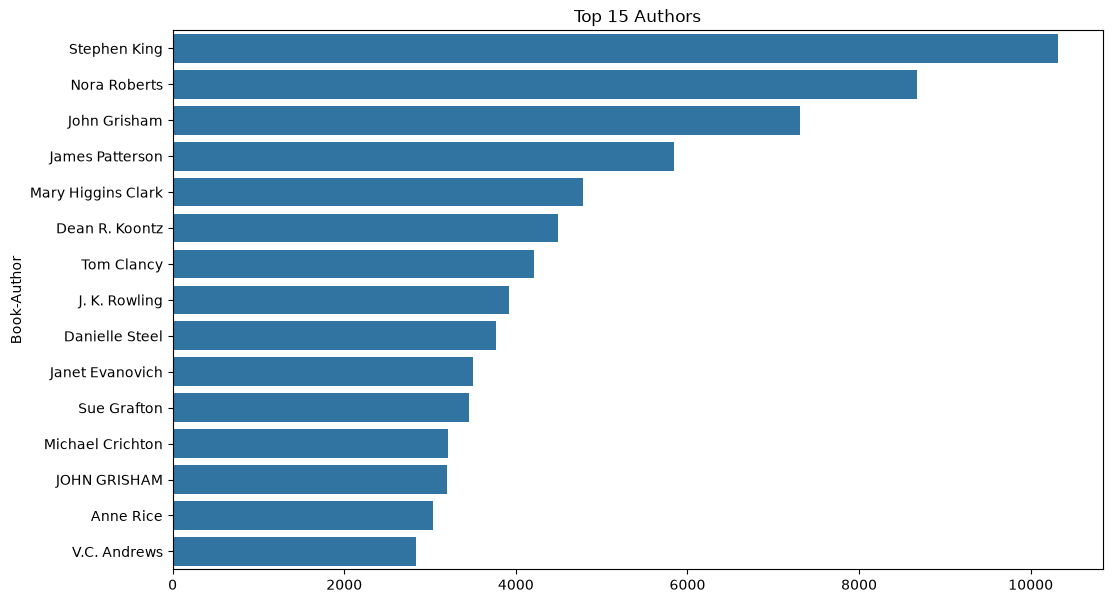

In [23]:
top_authors = (
    ml_df[
        "Book-Author"
    ]
    .value_counts()
    .head(15)
)

plt.figure(
    figsize=(12, 7)
)

sns.barplot(
    x=top_authors.values,
    y=top_authors.index
)

plt.title(
    "Top 15 Authors"
)

plt.show()

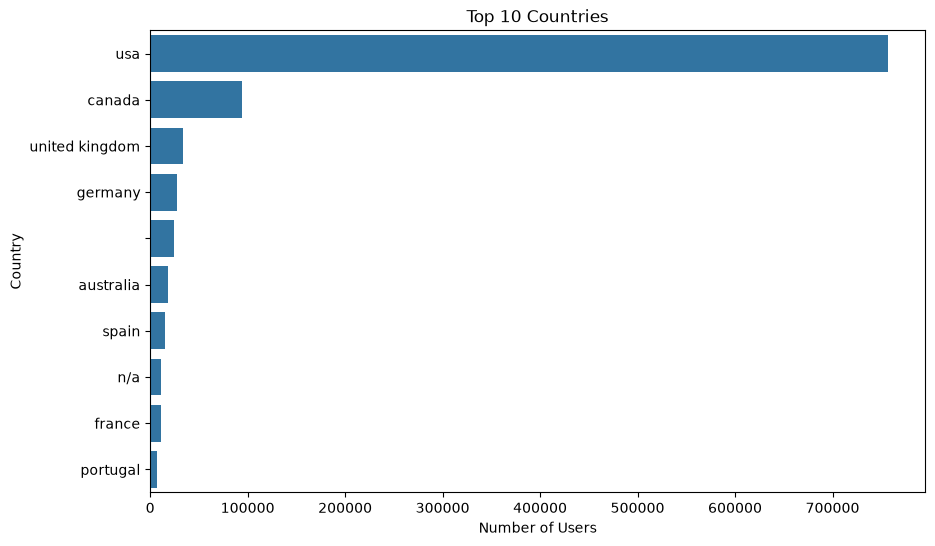

In [25]:
country_users = (
    ml_df[
        "Country"
    ]
    .value_counts()
    .head(10)
)

plt.figure(
    figsize=(10, 6)
)

sns.barplot(
    x=country_users.values,
    y=country_users.index
)

plt.title(
    "Top 10 Countries"
)

plt.xlabel(
    "Number of Users"
)

plt.ylabel(
    "Country"
)

plt.show()

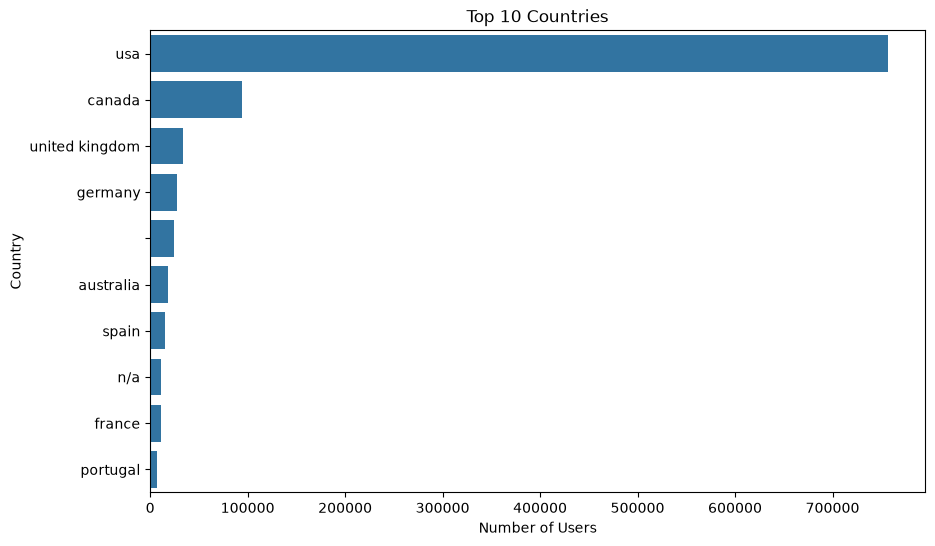

In [26]:
country_users = (
    ml_df[
        "Country"
    ]
    .value_counts()
    .head(10)
)

plt.figure(
    figsize=(10, 6)
)

sns.barplot(
    x=country_users.values,
    y=country_users.index
)

plt.title(
    "Top 10 Countries"
)

plt.xlabel(
    "Number of Users"
)

plt.ylabel(
    "Country"
)

plt.show()

In [27]:
ratings_df = ml_df[
    ml_df[
        "Book-Rating"
    ] > 0
].copy()

print(
    "All interactions:",
    len(ml_df)
)

print(
    "Explicit ratings:",
    len(ratings_df)
)

print(
    "Users:",
    ratings_df[
        "User-ID"
    ].nunique()
)

print(
    "Books:",
    ratings_df[
        "ISBN"
    ].nunique()
)

All interactions: 1044974
Explicit ratings: 389347
Users: 68091
Books: 149717


In [28]:
num_users = (
    ratings_df[
        "User-ID"
    ].nunique()
)

num_books = (
    ratings_df[
        "ISBN"
    ].nunique()
)

num_ratings = len(
    ratings_df
)

sparsity = 1 - (
    num_ratings
    /
    (
        num_users
        * num_books
    )
)

print(
    "Sparsity:",
    round(
        sparsity * 100,
        4
    ),
    "%"
)

Sparsity: 99.9962 %


In [29]:
user_counts = (
    ratings_df[
        "User-ID"
    ]
    .value_counts()
)

book_counts = (
    ratings_df[
        "ISBN"
    ]
    .value_counts()
)

print(
    user_counts.describe()
)

print(
    book_counts.describe()
)

count    68091.000000
mean         5.718039
std         42.023191
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max       7003.000000
Name: count, dtype: float64
count    149717.000000
mean          2.600553
std           8.211036
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max         707.000000
Name: count, dtype: float64


In [30]:
min_user_ratings = 5
min_book_ratings = 5

ratings_filtered = ratings_df[
    ratings_df[
        "User-ID"
    ].isin(
        user_counts[
            user_counts
            >= min_user_ratings
        ].index
    )
    &
    ratings_df[
        "ISBN"
    ].isin(
        book_counts[
            book_counts
            >= min_book_ratings
        ].index
    )
].copy()

print(
    "Original:",
    len(ratings_df)
)

print(
    "Filtered:",
    len(ratings_filtered)
)

print(
    "Users:",
    ratings_filtered[
        "User-ID"
    ].nunique()
)

print(
    "Books:",
    ratings_filtered[
        "ISBN"
    ].nunique()
)

Original: 389347
Filtered: 150856
Users: 12491
Books: 13820


In [33]:
from sklearn.model_selection import train_test_split

In [34]:
train_df, test_df = (
    train_test_split(
        ratings_filtered,
        test_size=0.20,
        random_state=42
    )
)

print(
    "Train:",
    train_df.shape
)

print(
    "Test:",
    test_df.shape
)

Train: (120684, 12)
Test: (30172, 12)


In [35]:
train_users = set(
    train_df[
        "User-ID"
    ]
)

train_books = set(
    train_df[
        "ISBN"
    ]
)

test_known = test_df[
    test_df[
        "User-ID"
    ].isin(
        train_users
    )
    &
    test_df[
        "ISBN"
    ].isin(
        train_books
    )
].copy()

print(
    "Original Test:",
    len(test_df)
)

print(
    "Known Test:",
    len(test_known)
)

Original Test: 30172
Known Test: 29825


In [36]:
book_stats = (
    train_df
    .groupby("ISBN")
    ["Book-Rating"]
    .agg(
        average_rating="mean",
        number_of_ratings="count"
    )
    .reset_index()
)

book_stats.head()

,ISBN,average_rating,number_of_ratings
0,0002005018,7.333333,6
1,0002251760,8.800000,5
2,0002259834,7.000000,3
3,0002558122,8.000000,3
4,0003300277,8.250000,4


In [37]:
C = (
    book_stats[
        "average_rating"
    ].mean()
)

m = (
    book_stats[
        "number_of_ratings"
    ].quantile(0.90)
)

book_stats[
    "weighted_rating"
] = (
    (
        book_stats[
            "number_of_ratings"
        ]
        /
        (
            book_stats[
                "number_of_ratings"
            ]
            + m
        )
    )
    *
    book_stats[
        "average_rating"
    ]
    +
    (
        m
        /
        (
            book_stats[
                "number_of_ratings"
            ]
            + m
        )
    )
    * C
)

In [38]:
popular_books = (
    book_stats[
        book_stats[
            "number_of_ratings"
        ] >= 20
    ]
    .sort_values(
        "weighted_rating",
        ascending=False
    )
)

popular_top10 = (
    popular_books
    .head(10)
    .merge(
        books[
            [
                "ISBN",
                "Book-Title",
                "Book-Author",
                "Publisher"
            ]
        ],
        on="ISBN",
        how="left"
    )
)

display(
    popular_top10[
        [
            "Book-Title",
            "Book-Author",
            "number_of_ratings",
            "average_rating",
            "weighted_rating"
        ]
    ]
)

,Book-Title,Book-Author,number_of_ratings,average_rating,weighted_rating
0,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,90,9.388889,9.123023
1,"The Return of the King (The Lord of the Rings,...",J.R.R. TOLKIEN,53,9.433962,9.016620
2,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,278,9.010791,8.936147
3,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,278,9.010791,8.936147
4,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,71,9.225352,8.933675
5,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,71,9.225352,8.933675
6,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,96,9.125000,8.912951
7,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,381,8.960630,8.907446
8,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,381,8.960630,8.907446
9,To Kill a Mockingbird,Harper Lee,125,9.048000,8.888475


In [40]:
from scipy.sparse import csr_matrix

In [41]:
user_book_matrix = (
    train_df
    .pivot_table(
        index="User-ID",
        columns="ISBN",
        values="Book-Rating",
        fill_value=0
    )
)

user_book_sparse = csr_matrix(
    user_book_matrix.values
)

print(
    "User-Book Matrix:",
    user_book_matrix.shape
)

User-Book Matrix: (12281, 13779)


In [42]:
user_knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)

user_knn.fit(
    user_book_sparse
)

print(
    "User-Based CF trained"
)

User-Based CF trained


In [43]:
def recommend_user_cf(
    user_id,
    n=10
):

    if user_id not in user_book_matrix.index:

        return pd.DataFrame()

    user_index = (
        user_book_matrix
        .index
        .get_loc(
            user_id
        )
    )

    n_neighbors = min(
        51,
        len(
            user_book_matrix
        )
    )

    distances, indices = (
        user_knn.kneighbors(
            user_book_sparse[
                user_index
            ],
            n_neighbors=n_neighbors
        )
    )

    neighbor_indices = (
        indices.flatten()[1:]
    )

    neighbor_distances = (
        distances.flatten()[1:]
    )

    neighbor_users = (
        user_book_matrix
        .index[
            neighbor_indices
        ]
    )

    similarities = (
        1
        - neighbor_distances
    )

    similarity_df = pd.DataFrame({
        "User-ID":
            neighbor_users,

        "similarity":
            similarities
    })

    neighbor_ratings = (
        train_df[
            train_df[
                "User-ID"
            ].isin(
                neighbor_users
            )
        ]
        .merge(
            similarity_df,
            on="User-ID",
            how="left"
        )
    )

    # Highly rated books
    neighbor_ratings = (
        neighbor_ratings[
            neighbor_ratings[
                "Book-Rating"
            ] >= 7
        ]
    )

    seen_books = set(
        train_df[
            train_df[
                "User-ID"
            ] == user_id
        ]["ISBN"]
    )

    neighbor_ratings = (
        neighbor_ratings[
            ~neighbor_ratings[
                "ISBN"
            ].isin(
                seen_books
            )
        ]
    )

    if neighbor_ratings.empty:

        return pd.DataFrame()

    recommendations = (
        neighbor_ratings
        .assign(
            weighted_score=
            neighbor_ratings[
                "Book-Rating"
            ]
            *
            neighbor_ratings[
                "similarity"
            ]
        )
        .groupby("ISBN")
        .agg(
            weighted_sum=(
                "weighted_score",
                "sum"
            ),
            similarity_sum=(
                "similarity",
                "sum"
            ),
            number_of_ratings=(
                "Book-Rating",
                "count"
            )
        )
        .reset_index()
    )

    recommendations[
        "score"
    ] = (
        recommendations[
            "weighted_sum"
        ]
        /
        recommendations[
            "similarity_sum"
        ].replace(
            0,
            np.nan
        )
    )

    recommendations = (
        recommendations
        .dropna(
            subset=["score"]
        )
        .sort_values(
            [
                "score",
                "number_of_ratings"
            ],
            ascending=[
                False,
                False
            ]
        )
        .head(n)
    )

    recommendations = (
        recommendations.merge(
            books[
                [
                    "ISBN",
                    "Book-Title",
                    "Book-Author"
                ]
            ],
            on="ISBN",
            how="left"
        )
    )

    return recommendations[
        [
            "ISBN",
            "Book-Title",
            "Book-Author",
            "score",
            "number_of_ratings"
        ]
    ]

In [44]:
sample_user = (
    user_book_matrix
    .index[0]
)

print(
    "User:",
    sample_user
)

display(
    recommend_user_cf(
        sample_user,
        10
    )
)

User: 8


,ISBN,Book-Title,Book-Author,score,number_of_ratings
0,0440212561,Outlander,DIANA GABALDON,10.0,1
1,0446310786,To Kill a Mockingbird,Harper Lee,10.0,1
2,0684874350,ANGELA'S ASHES,Frank McCourt,10.0,1
3,0553377868,The Flanders Panel,ARTURO PEREZ-REVERTE,9.0,2
4,0060929790,One Hundred Years of Solitude,Gabriel Garcia Marquez,9.0,1
5,0060953691,La Cucina: A Novel of Rapture,Lily Prior,9.0,1
6,0140092501,Chaos: Making a New Science,James Gleick,9.0,1
7,0486264645,Heart of Darkness (Dover Thrift Editions),Joseph Conrad,9.0,1
8,0671510053,SHIPPING NEWS,Annie Proulx,9.0,1
9,0836218833,Attack Of The Deranged Mutant Killer Snow Goons,Bill Watterson,9.0,1


In [45]:
book_user_matrix = (
    train_df
    .pivot_table(
        index="ISBN",
        columns="User-ID",
        values="Book-Rating",
        fill_value=0
    )
)

book_user_sparse = csr_matrix(
    book_user_matrix.values
)

print(
    "Book-User Matrix:",
    book_user_matrix.shape
)

Book-User Matrix: (13779, 12281)


In [46]:
item_knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)

item_knn.fit(
    book_user_sparse
)

print(
    "Item-Based CF trained"
)

Item-Based CF trained


In [48]:
def recommend_similar_books(
    isbn,
    n=10
):

    if isbn not in book_user_matrix.index:

        return pd.DataFrame()

    book_index = (
        book_user_matrix
        .index
        .get_loc(
            isbn
        )
    )

    n_neighbors = min(
        n + 1,
        len(
            book_user_matrix
        )
    )

    distances, indices = (
        item_knn.kneighbors(
            book_user_sparse[
                book_index
            ],
            n_neighbors=n_neighbors
        )
    )

    recommended_isbns = (
        book_user_matrix
        .index[
            indices.flatten()[1:]
        ]
    )

    similarities = (
        1
        - distances.flatten()[1:]
    )

    result = pd.DataFrame({
        "ISBN":
            recommended_isbns,

        "similarity":
            similarities
    })

    result = result.merge(
        books[
            [
                "ISBN",
                "Book-Title",
                "Book-Author"
            ]
        ],
        on="ISBN",
        how="left"
    )

    return result[
        [
            "ISBN",
            "Book-Title",
            "Book-Author",
            "similarity"
        ]
    ]

In [49]:
sample_isbn = (
    book_user_matrix
    .index[0]
)

print(
    "Selected ISBN:",
    sample_isbn
)

display(
    recommend_similar_books(
        sample_isbn,
        10
    )
)

Selected ISBN: 0002005018


,ISBN,Book-Title,Book-Author,similarity
0,0020811853,POSTCARDS,E. Annie Proulx,0.461365
1,0446378445,In search of excellence: Lessons from America'...,Thomas J Peters,0.246757
2,0688077080,Prayer for Owen Meany,John Irving,0.212485
3,0140017917,The Power and the Glory,Graham Greene,0.204479
4,0140092501,Chaos: Making a New Science,James Gleick,0.201485
5,0312199406,Night of Many Dreams : A Novel,Gail Tsukiyama,0.200928
6,0553135457,Sophies Choice,William Styron,0.190281
7,0440214009,Treasures,Belva Plain,0.186270
8,0143012738,The Corner Garden,Lesley Krueger,0.182157
9,0449912639,Girls : A Novel (Ballantine Reader's Circle),FREDERICK BUSCH,0.171045


In [52]:
from scipy.sparse import csr_matrix

from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.metrics import mean_squared_error, mean_absolute_error

import numpy as np
import pandas as pd
import pickle

print("Libraries imported successfully")

Libraries imported successfully


In [53]:
# Average duplicate user-book ratings if any
matrix_data = (
    train_df
    .groupby(
        ["User-ID", "ISBN"],
        as_index=False
    )["Book-Rating"]
    .mean()
)

# Unique IDs
user_ids = matrix_data["User-ID"].unique()
book_ids = matrix_data["ISBN"].unique()

# ID → matrix index
user_to_index = {
    user_id: i
    for i, user_id in enumerate(user_ids)
}

book_to_index = {
    isbn: i
    for i, isbn in enumerate(book_ids)
}

# Matrix index → ID
index_to_user = {
    i: user_id
    for user_id, i in user_to_index.items()
}

index_to_book = {
    i: isbn
    for isbn, i in book_to_index.items()
}

# Matrix coordinates
rows = (
    matrix_data["User-ID"]
    .map(user_to_index)
    .values
)

cols = (
    matrix_data["ISBN"]
    .map(book_to_index)
    .values
)

values = (
    matrix_data["Book-Rating"]
    .astype("float32")
    .values
)

# Sparse User × Book matrix
user_book_sparse = csr_matrix(
    (
        values,
        (rows, cols)
    ),
    shape=(
        len(user_ids),
        len(book_ids)
    ),
    dtype=np.float32
)

print(
    "Sparse Matrix Shape:",
    user_book_sparse.shape
)

print(
    "Stored Ratings:",
    user_book_sparse.nnz
)

Sparse Matrix Shape: (12281, 13779)
Stored Ratings: 117985


In [54]:
n_components = min(
    50,
    user_book_sparse.shape[0] - 1,
    user_book_sparse.shape[1] - 1
)

n_components = max(
    1,
    n_components
)

svd_model = TruncatedSVD(
    n_components=n_components,
    random_state=42
)

user_factors_svd = (
    svd_model.fit_transform(
        user_book_sparse
    )
)

book_factors_svd = (
    svd_model.components_.T
)

print(
    "SVD trained successfully"
)

print(
    "User Factors:",
    user_factors_svd.shape
)

print(
    "Book Factors:",
    book_factors_svd.shape
)

SVD trained successfully
User Factors: (12281, 50)
Book Factors: (13779, 50)


In [55]:
def predict_svd_rating(
    user_id,
    isbn
):

    if user_id not in user_to_index:
        return np.nan

    if isbn not in book_to_index:
        return np.nan

    user_index = (
        user_to_index[user_id]
    )

    book_index = (
        book_to_index[isbn]
    )

    prediction = np.dot(
        user_factors_svd[
            user_index
        ],
        book_factors_svd[
            book_index
        ]
    )

    # Rating range = 1 to 10
    prediction = np.clip(
        prediction,
        1,
        10
    )

    return float(prediction)

In [56]:
test_known = test_df[
    test_df["User-ID"].isin(
        user_to_index.keys()
    )
    &
    test_df["ISBN"].isin(
        book_to_index.keys()
    )
].copy()

print(
    "Original Test Rows:",
    len(test_df)
)

print(
    "Known Test Rows:",
    len(test_known)
)

Original Test Rows: 30172
Known Test Rows: 29825


In [58]:
svd_actual = []
svd_predicted = []

for _, row in test_known.iterrows():

    prediction = predict_svd_rating(
        row["User-ID"],
        row["ISBN"]
    )

    if not np.isnan(prediction):

        svd_actual.append(
            float(
                row["Book-Rating"]
            )
        )

        svd_predicted.append(
            prediction
        )

svd_rmse = np.sqrt(
    mean_squared_error(
        svd_actual,
        svd_predicted
    )
)

svd_mae = mean_absolute_error(
    svd_actual,
    svd_predicted
)

print(
    "SVD RMSE:",
    round(svd_rmse, 4)
)

print(
    "SVD MAE:",
    round(svd_mae, 4)
)

print(
    "Evaluated Ratings:",
    len(svd_actual)
)

SVD RMSE: 6.9192
SVD MAE: 6.6648
Evaluated Ratings: 29825


In [59]:
def recommend_svd(
    user_id,
    n=10
):

    if user_id not in user_to_index:

        print("User not found")
        return pd.DataFrame()

    user_index = (
        user_to_index[user_id]
    )

    # Predict every book score
    scores = np.dot(
        book_factors_svd,
        user_factors_svd[
            user_index
        ]
    )

    scores = np.clip(
        scores,
        1,
        10
    )

    # Books already rated
    seen_books = set(
        train_df[
            train_df[
                "User-ID"
            ] == user_id
        ]["ISBN"]
    )

    sorted_indices = np.argsort(
        scores
    )[::-1]

    recommendations = []

    for book_index in sorted_indices:

        isbn = (
            index_to_book[
                book_index
            ]
        )

        if isbn in seen_books:
            continue

        recommendations.append({
            "ISBN":
                isbn,

            "Predicted-Rating":
                round(
                    float(
                        scores[
                            book_index
                        ]
                    ),
                    3
                )
        })

        if len(recommendations) >= n:
            break

    result = pd.DataFrame(
        recommendations
    )

    if result.empty:
        return result

    result = result.merge(
        books[
            [
                "ISBN",
                "Book-Title",
                "Book-Author"
            ]
        ].drop_duplicates(
            "ISBN"
        ),
        on="ISBN",
        how="left"
    )

    return result[
        [
            "ISBN",
            "Book-Title",
            "Book-Author",
            "Predicted-Rating"
        ]
    ]

In [60]:
sample_user = (
    train_df[
        "User-ID"
    ]
    .value_counts()
    .index[0]
)

print(
    "Selected User:",
    sample_user
)

display(
    recommend_svd(
        sample_user,
        10
    )
)

Selected User: 11676


,ISBN,Book-Title,Book-Author,Predicted-Rating
0,0671876465,Mirror Dance,Lois McMaster Bujold,1.0
1,0140707344,Hamlet (The New Penguin Shakespeare),William Shakespeare,1.0
2,0140238719,Drawing Blood Uk,Poppy Z Brite,1.0
3,9726101794,As mulheres deviam vir com livro de instruÃ§Ãµ...,Manuel Jorge Marmelo,1.0
4,055357535X,The Stories of Eva Luna,Isabel Allende,1.0
5,0062502727,Crossing to Avalon: A Woman's Midlife Pilgrimage,Jean Shinoda Bolen,1.0
6,0886776287,Sing the Four Quarters (Daw Book Collectors),Tanya Huff,1.0
7,0553290991,Nightfall (Bantam Spectra Book),Isaac Asimov,1.0
8,0553296124,Heir to the Empire (Star Wars: The Thrawn Tril...,Timothy Zahn,1.0
9,1573220426,Kitchen Table Wisdom: Stories That Heal,Rachel Naomi Remen,1.0


In [61]:
nmf_components = min(
    30,
    user_book_sparse.shape[0],
    user_book_sparse.shape[1]
)

nmf_components = max(
    1,
    nmf_components
)

nmf_model = NMF(
    n_components=nmf_components,
    init="nndsvda",
    random_state=42,
    max_iter=100
)

user_factors_nmf = (
    nmf_model.fit_transform(
        user_book_sparse
    )
)

book_factors_nmf = (
    nmf_model.components_.T
)

print(
    "NMF trained successfully"
)

print(
    "User Factors:",
    user_factors_nmf.shape
)

print(
    "Book Factors:",
    book_factors_nmf.shape
)

NMF trained successfully
User Factors: (12281, 30)
Book Factors: (13779, 30)


In [62]:
def predict_nmf_rating(
    user_id,
    isbn
):

    if user_id not in user_to_index:
        return np.nan

    if isbn not in book_to_index:
        return np.nan

    user_index = (
        user_to_index[user_id]
    )

    book_index = (
        book_to_index[isbn]
    )

    prediction = np.dot(
        user_factors_nmf[
            user_index
        ],
        book_factors_nmf[
            book_index
        ]
    )

    prediction = np.clip(
        prediction,
        1,
        10
    )

    return float(prediction)

In [65]:
nmf_actual = []
nmf_predicted = []

for _, row in test_known.iterrows():

    prediction = predict_nmf_rating(
        row["User-ID"],
        row["ISBN"]
    )

    if not np.isnan(prediction):

        nmf_actual.append(
            float(
                row["Book-Rating"]
            )
        )

        nmf_predicted.append(
            prediction
        )

nmf_rmse = np.sqrt(
    mean_squared_error(
        nmf_actual,
        nmf_predicted
    )
)

nmf_mae = mean_absolute_error(
    nmf_actual,
    nmf_predicted
)

print(
    "NMF RMSE:",
    round(nmf_rmse, 4)
)

print(
    "NMF MAE:",
    round(nmf_mae, 4)
)

print(
    "Evaluated Ratings:",
    len(nmf_actual)
)

NMF RMSE: 6.9522
NMF MAE: 6.7071
Evaluated Ratings: 29825


In [66]:
model_comparison = pd.DataFrame({
    "Model": [
        "Truncated SVD",
        "NMF"
    ],

    "RMSE": [
        svd_rmse,
        nmf_rmse
    ],

    "MAE": [
        svd_mae,
        nmf_mae
    ]
})

display(
    model_comparison
)

,Model,RMSE,MAE
0,Truncated SVD,6.919167,6.664798
1,NMF,6.952235,6.707087


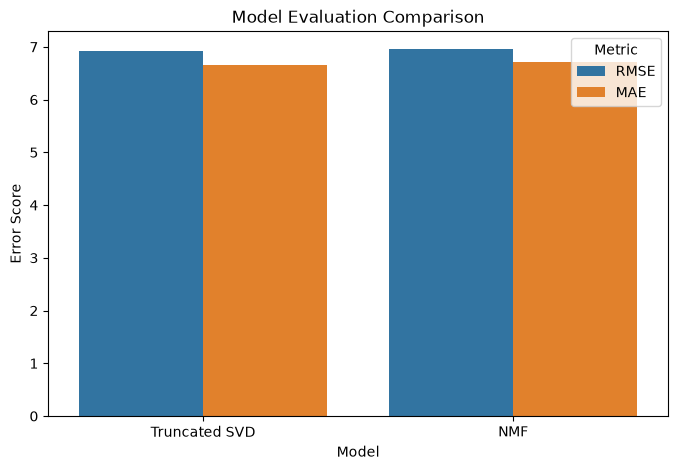

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

comparison_plot = (
    model_comparison
    .melt(
        id_vars="Model",
        var_name="Metric",
        value_name="Score"
    )
)

plt.figure(
    figsize=(8, 5)
)

sns.barplot(
    data=comparison_plot,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title(
    "Model Evaluation Comparison"
)

plt.xlabel(
    "Model"
)

plt.ylabel(
    "Error Score"
)

plt.show()

In [68]:
def precision_recall_at_k(
    recommended_books,
    actual_books,
    k=10
):

    recommended_books = (
        recommended_books[:k]
    )

    actual_books = set(
        actual_books
    )

    if len(actual_books) == 0:
        return 0.0, 0.0

    hits = len(
        set(
            recommended_books
        ).intersection(
            actual_books
        )
    )

    precision = (
        hits / k
    )

    recall = (
        hits /
        len(actual_books)
    )

    return (
        precision,
        recall
    )

In [69]:
evaluation_users = (
    test_known[
        "User-ID"
    ]
    .drop_duplicates()
    .head(100)
    .tolist()
)

precision_scores = []
recall_scores = []

for user_id in evaluation_users:

    actual_books = (
        test_known[
            test_known[
                "User-ID"
            ] == user_id
        ]["ISBN"]
        .tolist()
    )

    recommendations = (
        recommend_svd(
            user_id,
            10
        )
    )

    if recommendations.empty:
        continue

    predicted_books = (
        recommendations[
            "ISBN"
        ]
        .tolist()
    )

    precision, recall = (
        precision_recall_at_k(
            predicted_books,
            actual_books,
            k=10
        )
    )

    precision_scores.append(
        precision
    )

    recall_scores.append(
        recall
    )

precision_at_10 = (
    np.mean(
        precision_scores
    )
    if precision_scores
    else 0
)

recall_at_10 = (
    np.mean(
        recall_scores
    )
    if recall_scores
    else 0
)

print(
    "Evaluated Users:",
    len(
        precision_scores
    )
)

print(
    "Precision@10:",
    round(
        precision_at_10,
        4
    )
)

print(
    "Recall@10:",
    round(
        recall_at_10,
        4
    )
)

Evaluated Users: 100
Precision@10: 0.031
Recall@10: 0.0167


In [70]:
model_bundle = {
    "svd_model":
        svd_model,

    "user_factors_svd":
        user_factors_svd,

    "book_factors_svd":
        book_factors_svd,

    "nmf_model":
        nmf_model,

    "user_factors_nmf":
        user_factors_nmf,

    "book_factors_nmf":
        book_factors_nmf,

    "user_to_index":
        user_to_index,

    "book_to_index":
        book_to_index,

    "index_to_user":
        index_to_user,

    "index_to_book":
        index_to_book
}

with open(
    "recommendation_models.pkl",
    "wb"
) as file:

    pickle.dump(
        model_bundle,
        file
    )

with open(
    "books.pkl",
    "wb"
) as file:

    pickle.dump(
        books,
        file
    )

print(
    "Models saved successfully"
)

print("\nFINAL MODEL RESULTS")

print(
    "SVD RMSE:",
    round(
        svd_rmse,
        4
    )
)

print(
    "SVD MAE:",
    round(
        svd_mae,
        4
    )
)

print(
    "NMF RMSE:",
    round(
        nmf_rmse,
        4
    )
)

print(
    "NMF MAE:",
    round(
        nmf_mae,
        4
    )
)

print(
    "Precision@10:",
    round(
        precision_at_10,
        4
    )
)

print(
    "Recall@10:",
    round(
        recall_at_10,
        4
    )
)

print(
    "\nProject Model Building and Evaluation Completed"
)

Models saved successfully

FINAL MODEL RESULTS
SVD RMSE: 6.9192
SVD MAE: 6.6648
NMF RMSE: 6.9522
NMF MAE: 6.7071
Precision@10: 0.031
Recall@10: 0.0167

Project Model Building and Evaluation Completed
